# Lightweight CNN Models - Individual Training & Testing
## Train and evaluate each model separately

This notebook trains and evaluates each model in separate sections:
- VGG16
- ResNet18
- EfficientNet-B0
- MobileNetV1
- MobileNetV3-Small
- MobileNetV2-0.5×

Dataset: WM-811K (32×32×3 input images, 8 classes)

## 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

# TensorFlow imports
import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Conv2D, MaxPooling2D
from tensorflow.keras.layers import BatchNormalization, Activation, Add
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import VGG16, MobileNet, MobileNetV2, MobileNetV3Small, EfficientNetB0

# PyTorch imports for ResNet18
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import DataLoader, TensorDataset

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available (PyTorch): {torch.cuda.is_available()}")

2025-10-18 14:25:48.817246: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1760797549.001863      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1760797549.057858      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow version: 2.18.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PyTorch version: 2.6.0+cu124
CUDA Available (PyTorch): True


## 2. Setup Configuration

In [2]:
# Hyperparameters
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001
INPUT_SHAPE = (32, 32, 3)
NUM_CLASSES = 8

# Paths
DATA_DIR = '/kaggle/input/my-wm-811k/'
TRAIN_DATA = os.path.join(DATA_DIR, 'train_data.csv')
TEST_DATA = os.path.join(DATA_DIR, 'test_data.csv')
OUTPUT_DIR = 'outputs/comparison_models/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Configuration:")
print(f"  Batch Size: {BATCH_SIZE}")
print(f"  Epochs: {EPOCHS}")
print(f"  Learning Rate: {LEARNING_RATE}")
print(f"  Input Shape: {INPUT_SHAPE}")
print(f"  Number of Classes: {NUM_CLASSES}")

Configuration:
  Batch Size: 32
  Epochs: 50
  Learning Rate: 0.001
  Input Shape: (32, 32, 3)
  Number of Classes: 8


## 3. Load and Prepare Dataset

In [27]:
import json
import ast

# Load training data (already preprocessed with 3 channels)
train_df = pd.read_csv(TRAIN_DATA)
print(f"Training data shape: {train_df.shape}")

# Parse JSON strings back to numpy arrays
X_train = np.array([np.array(json.loads(row)) for row in train_df['waferMap']])
y_train = np.array([np.array(json.loads(row)) for row in train_df['failureType']])

print(f"Training data loaded: X_train shape = {X_train.shape}, y_train shape = {y_train.shape}")

# Load test data (2D wafer maps - need one-hot encoding)
test_df = pd.read_csv(TEST_DATA)
print(f"Test data shape: {test_df.shape}")

# Convert waferMap column strings back to lists
test_df['waferMap'] = test_df['waferMap'].apply(ast.literal_eval)

# Extract wafer maps and labels
test_wafer_maps = np.array(test_df['waferMap'].tolist())
test_labels = test_df['failureType'].values

# Encode test labels
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_test_encoded = label_encoder.fit_transform(test_labels)
y_test = to_categorical(y_test_encoded, num_classes=NUM_CLASSES)

# Store class names globally for use in evaluation
CLASS_NAMES = label_encoder.classes_
print(f"Class names: {CLASS_NAMES}")

print(f"Test wafer maps shape (2D): {test_wafer_maps.shape}")
print(f"Test labels shape: {y_test.shape}")

# One-hot encode the test data (convert 2D to 3-channel format)
print("\nOne-hot encoding test data...")
X_test = np.zeros((len(test_wafer_maps), 32, 32, 3))
for w in range(len(test_wafer_maps)):
    for i in range(32):
        for j in range(32):
            value = int(test_wafer_maps[w, i, j])
            if value < 3:
                X_test[w, i, j, value] = 1

print(f"Test data encoded: X_test shape = {X_test.shape}")

# Create validation split from training data
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

print(f"\nDataset splits:")
print(f"  Training samples: {X_train.shape[0]}")
print(f"  Validation samples: {X_val.shape[0]}")
print(f"  Test samples: {X_test.shape[0]}")
print(f"  Classes: {NUM_CLASSES}")

Training data shape: (53000, 2)
Training data loaded: X_train shape = (53000, 32, 32, 3), y_train shape = (53000, 8)
Test data shape: (7894, 8)
Class names: ["[['Center']]" "[['Donut']]" "[['Edge-Loc']]" "[['Edge-Ring']]"
 "[['Loc']]" "[['Near-full']]" "[['Random']]" "[['Scratch']]"]
Test wafer maps shape (2D): (7894, 32, 32)
Test labels shape: (7894, 8)

One-hot encoding test data...
Test data encoded: X_test shape = (7894, 32, 32, 3)

Dataset splits:
  Training samples: 42400
  Validation samples: 10600
  Test samples: 7894
  Classes: 8


## 4. Define Helper Functions

In [29]:
def add_custom_classification_head(base_model, num_classes=8):
    """Add custom classification head for fair comparison"""
    x = base_model.output
    
    # Check if output is already 2D (batch, features)
    if len(x.shape) == 4:  # (batch, height, width, channels)
        x = GlobalAveragePooling2D()(x)
    elif len(x.shape) == 3:  # (batch, seq_len, features)
        x = tf.keras.layers.Flatten()(x)
    
    x = Dropout(0.3)(x)
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.2)(x)
    output = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=output)
    return model

def get_callbacks(model_name, output_dir):
    """Create callbacks for training"""
    checkpoint_path = os.path.join(output_dir, f'{model_name}_best.keras')
    
    callbacks = [
        EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=5,
            min_lr=1e-7,
            verbose=1
        ),
        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor='val_accuracy',
            save_best_only=True,
            verbose=1
        )
    ]
    return callbacks

def plot_training_history(history, model_name):
    """Plot training and validation accuracy/loss"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot accuracy
    axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
    axes[0].set_title(f'{model_name} - Accuracy', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot loss
    axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
    axes[1].set_title(f'{model_name} - Loss', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{model_name}_history.png'), dpi=300, bbox_inches='tight')
    plt.show()

def evaluate_model(model, model_name, X_test, y_test, class_names=None):
    """Evaluate model and print metrics"""
    print(f"\n{'='*60}")
    print(f"Evaluating {model_name} on Test Set")
    print(f"{'='*60}")
    
    # Evaluate
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    
    # Predictions
    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_test, axis=1)
    
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")
    
    # Use class names if provided
    target_names = class_names if class_names is not None else [str(i) for i in range(len(np.unique(y_true_classes)))]
    
    print(f"\nClassification Report:\n")
    print(classification_report(y_true_classes, y_pred_classes, target_names=target_names, digits=4))
    
    # Confusion matrix
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
                xticklabels=target_names, yticklabels=target_names)
    plt.title(f'{model_name} - Confusion Matrix', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{model_name}_confusion_matrix.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    return test_loss, test_acc

def evaluate_pytorch_model(model, model_name, X_test, y_test, class_names=None, device='cpu'):
    """Evaluate PyTorch model and print metrics"""
    print(f"\n{'='*60}")
    print(f"Evaluating {model_name} on Test Set")
    print(f"{'='*60}")
    
    model.eval()
    
    # Convert one-hot to class indices for PyTorch
    y_test_classes = np.argmax(y_test, axis=1)
    
    # Convert data to PyTorch tensors
    X_test_tensor = torch.FloatTensor(X_test).permute(0, 3, 1, 2).to(device)  # NHWC -> NCHW
    y_test_tensor = torch.LongTensor(y_test_classes).to(device)
    
    # Create DataLoader
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    # Get predictions
    all_preds = []
    all_labels = []
    total_loss = 0
    criterion = nn.CrossEntropyLoss()
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    
    test_loss = total_loss / len(test_loader)
    test_acc = accuracy_score(all_labels, all_preds)
    
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")
    
    # Use class names if provided
    target_names = class_names if class_names is not None else [str(i) for i in range(len(np.unique(all_labels)))]
    
    print(f"\nClassification Report:\n")
    print(classification_report(all_labels, all_preds, target_names=target_names, digits=4))
    
    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
                xticklabels=target_names, yticklabels=target_names)
    plt.title(f'{model_name} - Confusion Matrix', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{model_name}_confusion_matrix.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    return test_loss, test_acc

print("Helper functions defined successfully!")

Helper functions defined successfully!


## 5. Model 1: VGG16
### Build, Train, and Test VGG16

In [5]:
# Build VGG16
print("Building VGG16 model...")
base_vgg16 = VGG16(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
model_vgg16 = add_custom_classification_head(base_vgg16, NUM_CLASSES)

# Model summary
print(f"\nTotal Parameters: {model_vgg16.count_params():,}")
model_vgg16.summary()

Building VGG16 model...


I0000 00:00:1760797683.287983      37 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Total Parameters: 14,718,792


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,718,792 (56.15 MB)

 Trainable params: 14,718,792 (56.15 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Compile VGG16
model_vgg16.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train VGG16
print("\n" + "="*70)
print("Training VGG16")
print("="*70)

history_vgg16 = model_vgg16.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=get_callbacks('VGG16', OUTPUT_DIR),
    verbose=1
)

print("\nVGG16 training completed!")


Training VGG16
Epoch 1/50


I0000 00:00:1760797691.763719      95 service.cc:148] XLA service 0x7f1e18016fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1760797691.764319      95 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1760797692.361985      95 cuda_dnn.cc:529] Loaded cuDNN version 90300


   7/1325 ━━━━━━━━━━━━━━━━━━━━ 34s 26ms/step - accuracy: 0.1894 - loss: 2.1742   

I0000 00:00:1760797696.703787      95 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6910 - loss: 0.8513
Epoch 1: val_accuracy improved from -inf to 0.86151, saving model to outputs/comparison_models/VGG16_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 48s 29ms/step - accuracy: 0.6912 - loss: 0.8509 - val_accuracy: 0.8615 - val_loss: 0.3982 - learning_rate: 0.0010
Epoch 2/50
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8778 - loss: 0.3496
Epoch 2: val_accuracy improved from 0.86151 to 0.88387, saving model to outputs/comparison_models/VGG16_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 35s 27ms/step - accuracy: 0.8778 - loss: 0.3496 - val_accuracy: 0.8839 - val_loss: 0.3670 - learning_rate: 0.0010
Epoch 3/50
1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8998 - loss: 0.2904
Epoch 3: val_accuracy improved from 0.88387 to 0.90377, saving model to outputs/comparison_models/VGG16_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 35s 26ms/step - accuracy: 0.8998 - loss: 0.2904 - val_accuracy: 0.9038 - val_loss

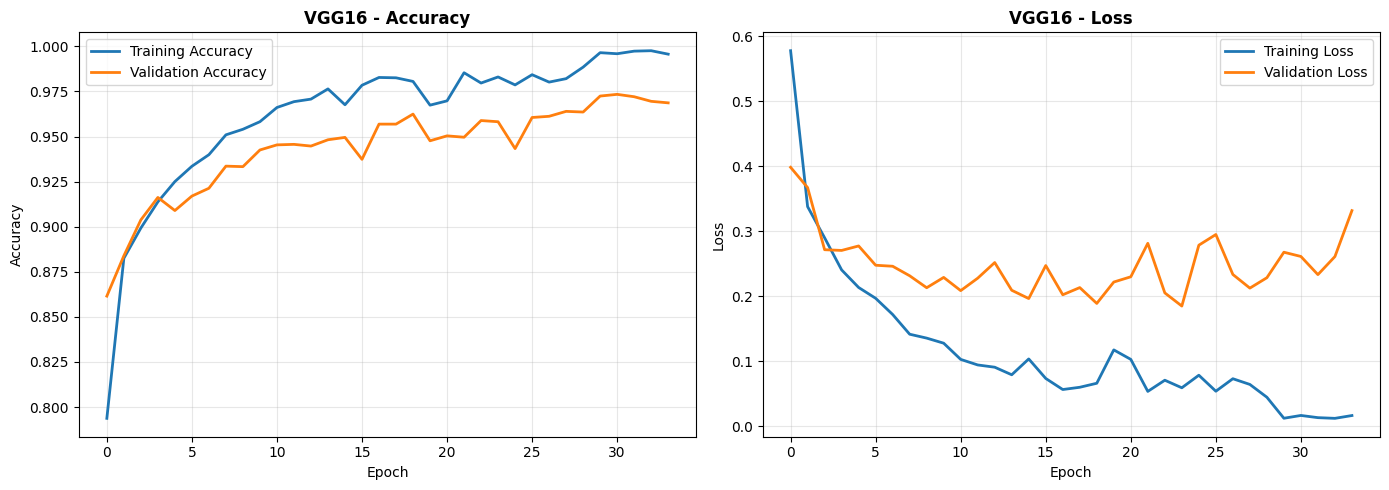

In [7]:
# Plot training history
plot_training_history(history_vgg16, 'VGG16')


Evaluating VGG16 on Test Set
Test Loss: 0.1721
Test Accuracy: 0.9554

Classification Report:

              precision    recall  f1-score   support

           0     0.9748    0.9748    0.9748       832
           1     0.9733    1.0000    0.9865       146
           2     0.9459    0.9841    0.9646      2772
           3     0.9725    0.9432    0.9576      1126
           4     0.9504    0.9615    0.9559      1973
           5     1.0000    1.0000    1.0000        95
           6     0.9786    0.8911    0.9328       257
           7     0.9394    0.8283    0.8804       693

    accuracy                         0.9554      7894
   macro avg     0.9669    0.9479    0.9566      7894
weighted avg     0.9555    0.9554    0.9549      7894



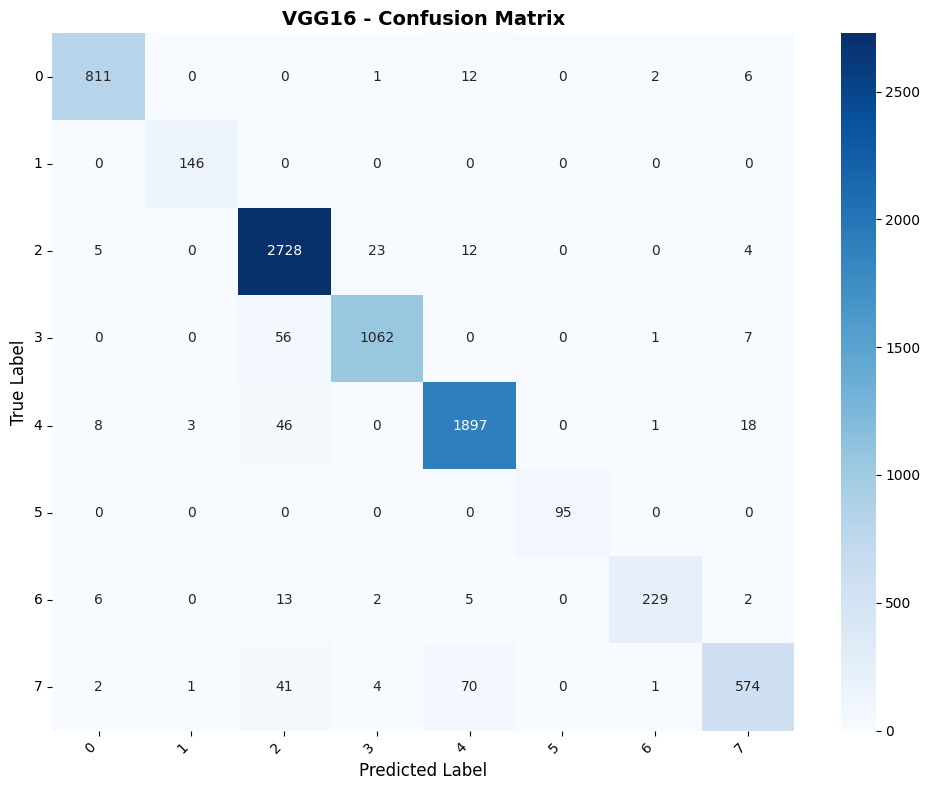

In [30]:
# Evaluate VGG16 on test set
vgg16_test_loss, vgg16_test_acc = evaluate_model(model_vgg16, 'VGG16', X_test, y_test)

## 6. Model 2: ResNet18 (PyTorch)
### Build, Train, and Test ResNet18 using PyTorch

In [17]:
# Build ResNet18 using PyTorch
print("Building ResNet18 model (PyTorch)...")

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load pre-trained ResNet18
model_resnet18_pytorch = models.resnet18(pretrained=True)

# Modify the final layer for 8 classes with custom head
num_features = model_resnet18_pytorch.fc.in_features
model_resnet18_pytorch.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_features, 32),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(32, NUM_CLASSES)
)

model_resnet18_pytorch = model_resnet18_pytorch.to(device)

# Count parameters
total_params = sum(p.numel() for p in model_resnet18_pytorch.parameters())
print(f"\nTotal Parameters: {total_params:,}")
print(model_resnet18_pytorch)

Building ResNet18 model (PyTorch)...
Using device: cuda

Total Parameters: 11,193,192
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, mo

In [18]:
# Train ResNet18 (PyTorch)
print("\n" + "="*70)
print("Training ResNet18 (PyTorch)")
print("="*70)

# Prepare data for PyTorch (NHWC -> NCHW)
X_train_torch = torch.FloatTensor(X_train).permute(0, 3, 1, 2)
y_train_torch = torch.LongTensor(np.argmax(y_train, axis=1))
X_val_torch = torch.FloatTensor(X_val).permute(0, 3, 1, 2)
y_val_torch = torch.LongTensor(np.argmax(y_val, axis=1))

# Create DataLoaders
train_dataset = TensorDataset(X_train_torch, y_train_torch)
val_dataset = TensorDataset(X_val_torch, y_val_torch)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Define loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_resnet18_pytorch.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5, verbose=True)

# Training loop
history_resnet18 = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
best_val_acc = 0
patience_counter = 0
patience = 10

for epoch in range(EPOCHS):
    # Training phase
    model_resnet18_pytorch.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model_resnet18_pytorch(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    train_loss = train_loss / len(train_loader)
    train_acc = train_correct / train_total
    
    # Validation phase
    model_resnet18_pytorch.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_resnet18_pytorch(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    val_loss = val_loss / len(val_loader)
    val_acc = val_correct / val_total
    
    # Store history
    history_resnet18['loss'].append(train_loss)
    history_resnet18['accuracy'].append(train_acc)
    history_resnet18['val_loss'].append(val_loss)
    history_resnet18['val_accuracy'].append(val_acc)
    
    # Learning rate scheduling
    scheduler.step(val_loss)
    
    # Print progress
    print(f'Epoch {epoch+1}/{EPOCHS} - Loss: {train_loss:.4f} - Acc: {train_acc:.4f} - Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f}')
    
    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model_resnet18_pytorch.state_dict(), os.path.join(OUTPUT_DIR, 'ResNet18_best.pth'))
        patience_counter = 0
        print(f'✓ Validation accuracy improved to {val_acc:.4f}. Model saved!')
    else:
        patience_counter += 1
    
    # Early stopping
    if patience_counter >= patience:
        print(f'\nEarly stopping triggered after {epoch+1} epochs')
        break

# Load best model
model_resnet18_pytorch.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, 'ResNet18_best.pth')))
print("\nResNet18 (PyTorch) training completed!")


Training ResNet18 (PyTorch)
Epoch 1/50 - Loss: 0.5239 - Acc: 0.8265 - Val Loss: 0.3224 - Val Acc: 0.8869
✓ Validation accuracy improved to 0.8869. Model saved!
Epoch 2/50 - Loss: 0.3353 - Acc: 0.8922 - Val Loss: 0.2774 - Val Acc: 0.9030
✓ Validation accuracy improved to 0.9030. Model saved!
Epoch 3/50 - Loss: 0.2660 - Acc: 0.9095 - Val Loss: 0.2838 - Val Acc: 0.9075
✓ Validation accuracy improved to 0.9075. Model saved!
Epoch 4/50 - Loss: 0.2226 - Acc: 0.9256 - Val Loss: 0.2010 - Val Acc: 0.9300
✓ Validation accuracy improved to 0.9300. Model saved!
Epoch 5/50 - Loss: 0.1869 - Acc: 0.9375 - Val Loss: 0.2016 - Val Acc: 0.9325
✓ Validation accuracy improved to 0.9325. Model saved!
Epoch 6/50 - Loss: 0.1622 - Acc: 0.9488 - Val Loss: 0.1801 - Val Acc: 0.9372
✓ Validation accuracy improved to 0.9372. Model saved!
Epoch 7/50 - Loss: 0.1305 - Acc: 0.9570 - Val Loss: 0.1544 - Val Acc: 0.9498
✓ Validation accuracy improved to 0.9498. Model saved!
Epoch 8/50 - Loss: 0.1107 - Acc: 0.9650 - Val L

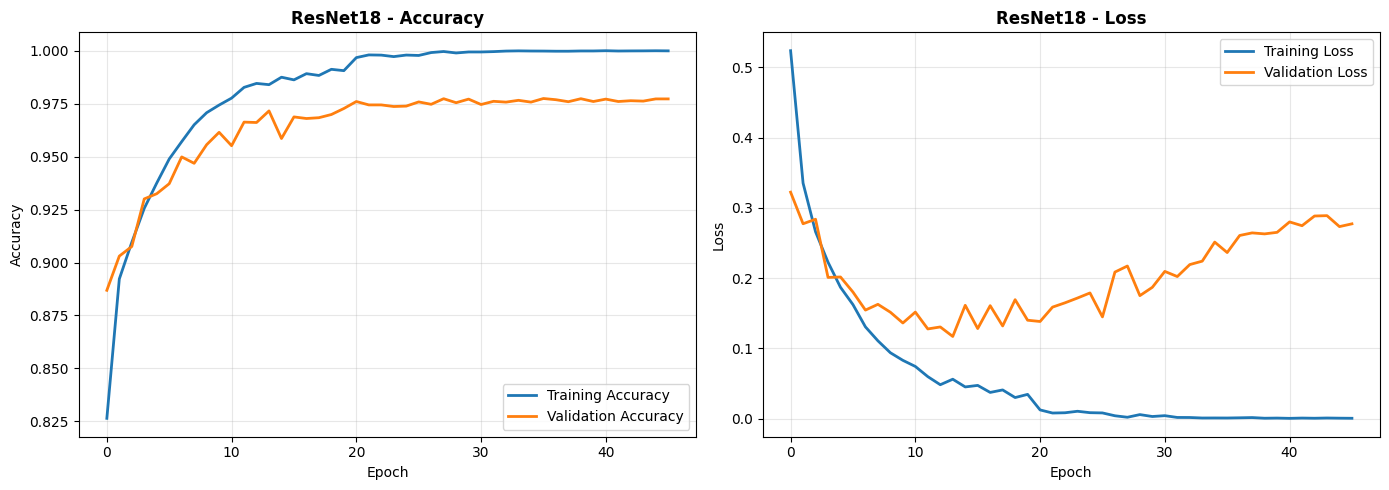

In [19]:
# Plot training history for ResNet18
class DummyHistory:
    def __init__(self, history_dict):
        self.history = history_dict

history_obj_resnet18 = DummyHistory(history_resnet18)
plot_training_history(history_obj_resnet18, 'ResNet18')


Evaluating ResNet18 on Test Set
Test Loss: 0.1573
Test Accuracy: 0.9861

Classification Report:

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       832
           1       0.97      1.00      0.98       146
           2       0.99      0.99      0.99      2772
           3       1.00      1.00      1.00      1126
           4       0.98      0.99      0.98      1973
           5       1.00      1.00      1.00        95
           6       1.00      0.97      0.98       257
           7       0.99      0.92      0.95       693

    accuracy                           0.99      7894
   macro avg       0.99      0.98      0.99      7894
weighted avg       0.99      0.99      0.99      7894



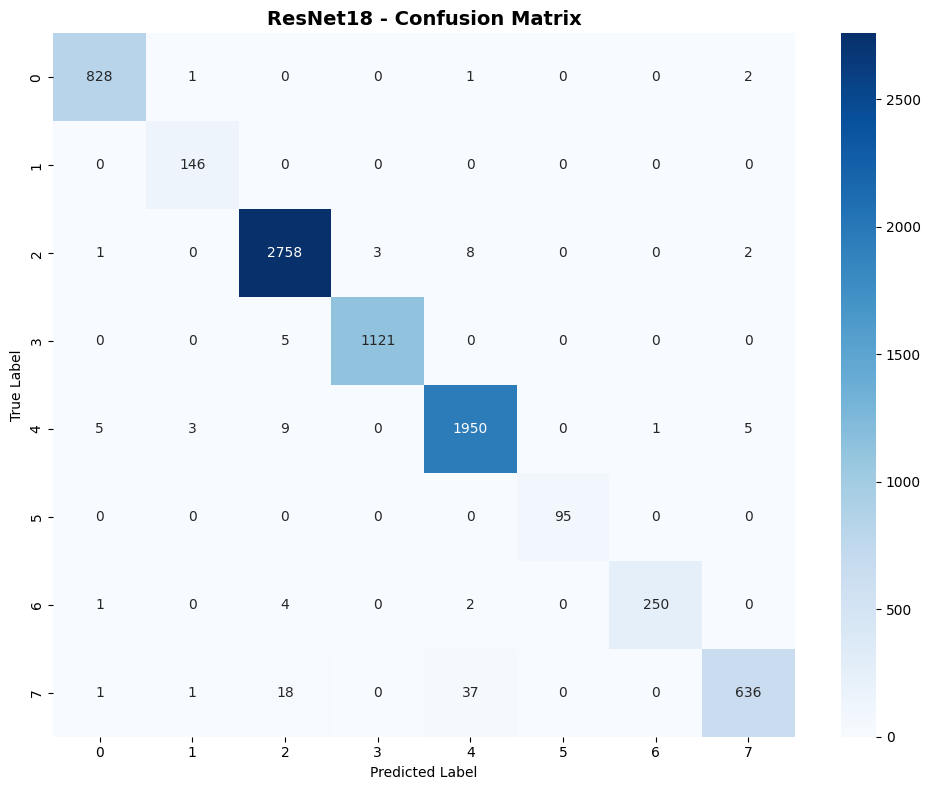

In [20]:
# Evaluate ResNet18 (PyTorch) on test set
resnet18_test_loss, resnet18_test_acc = evaluate_pytorch_model(
    model_resnet18_pytorch, 'ResNet18', X_test, y_test, device=device
)

## 7. Model 3: EfficientNet-B0
### Build, Train, and Test EfficientNet-B0

In [21]:
# Build EfficientNet-B0
print("Building EfficientNet-B0 model...")
base_effnet = EfficientNetB0(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
model_effnet = add_custom_classification_head(base_effnet, NUM_CLASSES)

# Model summary
print(f"\nTotal Parameters: {model_effnet.count_params():,}")
model_effnet.summary()

Building EfficientNet-B0 model...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Total Parameters: 4,059,819


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 32, 32, 3) │          0 │ input_layer_1[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 32, 32, 3) │          7 │ rescaling[0][0]   │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 32, 32, 3) │          0 │ normalization[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 33, 33, 3) │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 16, 16,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 16, 16,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 16, 16,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 16, 16,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 16, 16,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 16, 16,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 16, 16,    │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 16, 16,    │        512 │ block1a_se_excit

 Total params: 4,059,819 (15.49 MB)

 Trainable params: 4,017,796 (15.33 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [22]:
# Compile EfficientNet-B0
model_effnet.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train EfficientNet-B0
print("\n" + "="*70)
print("Training EfficientNet-B0")
print("="*70)

history_effnet = model_effnet.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=get_callbacks('EfficientNetB0', OUTPUT_DIR),
    verbose=1
)

print("\nEfficientNet-B0 training completed!")


Training EfficientNet-B0
Epoch 1/50


E0000 00:00:1760800427.242169      97 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1760800427.418707      97 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6808 - loss: 0.9208
Epoch 1: val_accuracy improved from -inf to 0.05189, saving model to outputs/comparison_models/EfficientNetB0_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 115s 29ms/step - accuracy: 0.6810 - loss: 0.9204 - val_accuracy: 0.0519 - val_loss: 6.8511 - learning_rate: 0.0010
Epoch 2/50
1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8626 - loss: 0.3840
Epoch 2: val_accuracy did not improve from 0.05189
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 28s 21ms/step - accuracy: 0.8626 - loss: 0.3839 - val_accuracy: 0.0445 - val_loss: 3.1197 - learning_rate: 0.0010
Epoch 3/50
1323/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8921 - loss: 0.3003
Epoch 3: val_accuracy did not improve from 0.05189
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 28s 21ms/step - accuracy: 0.8921 - loss: 0.3003 - val_accuracy: 0.0433 - val_loss: 7.0974 - learning_rate: 0.0010
Epoch 4/50
1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9011 - loss: 0.2

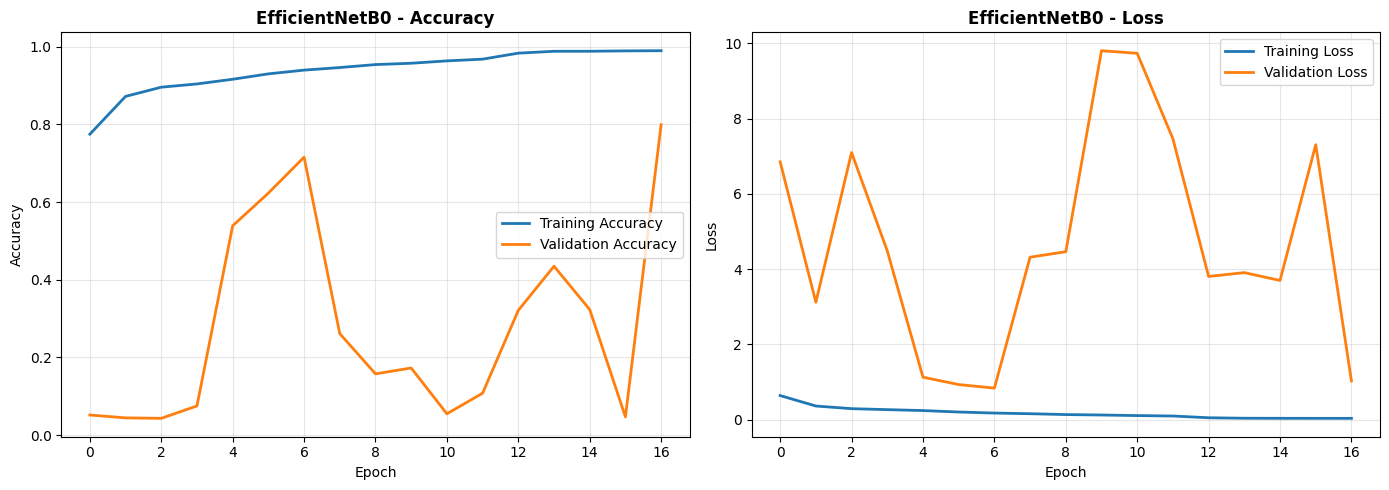

In [31]:
# Plot training history
plot_training_history(history_effnet, 'EfficientNetB0')


Evaluating EfficientNetB0 on Test Set
Test Loss: 1.4551
Test Accuracy: 0.4693

Classification Report:

              precision    recall  f1-score   support

           0     0.9160    0.2752    0.4233       832
           1     0.5122    0.7192    0.5983       146
           2     0.5817    0.4686    0.5191      2772
           3     0.2912    0.8295    0.4311      1126
           4     0.6661    0.4004    0.5002      1973
           5     0.8879    1.0000    0.9406        95
           6     0.3529    0.9611    0.5162       257
           7     1.0000    0.0087    0.0172       693

    accuracy                         0.4693      7894
   macro avg     0.6510    0.5828    0.4932      7894
weighted avg     0.6283    0.4693    0.4541      7894



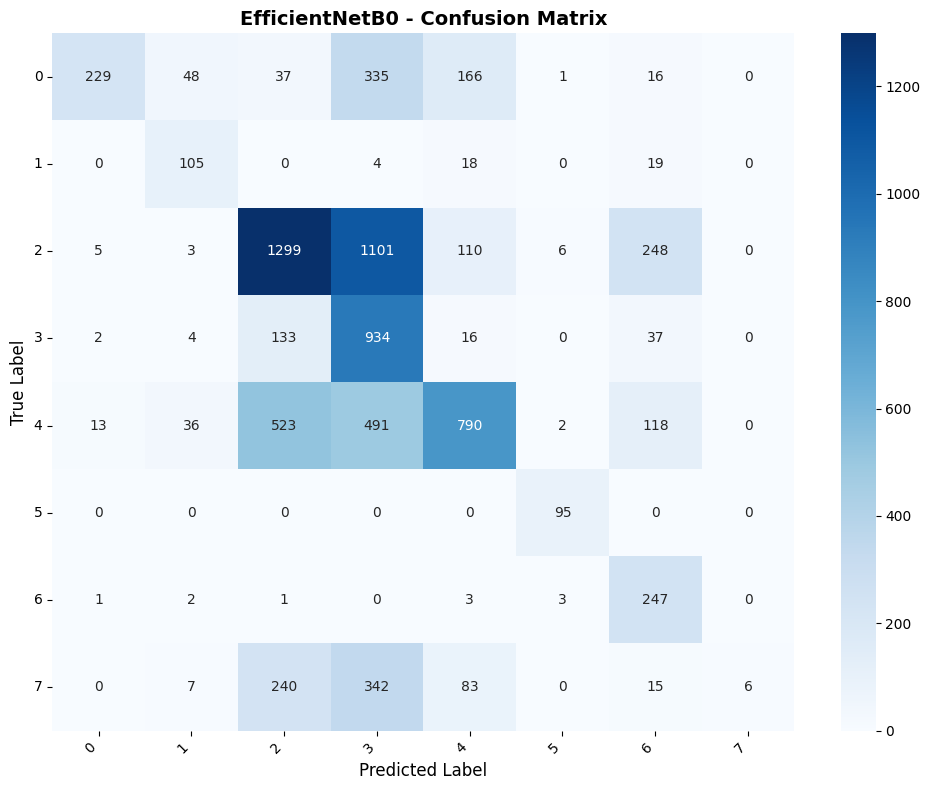

In [32]:
# Evaluate EfficientNet-B0 on test set
effnet_test_loss, effnet_test_acc = evaluate_model(model_effnet, 'EfficientNetB0', X_test, y_test)

## 8. Model 4: MobileNet-V1
### Build, Train, and Test MobileNet-V1

In [33]:
# Build MobileNet-V1
print("Building MobileNet-V1 model...")
base_mobilenet = MobileNet(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
model_mobilenet = add_custom_classification_head(base_mobilenet, NUM_CLASSES)

# Model summary
print(f"\nTotal Parameters: {model_mobilenet.count_params():,}")
model_mobilenet.summary()

Building MobileNet-V1 model...
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Total Parameters: 3,261,928


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 16, 16, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 16, 16, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 16, 16, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 16, 16, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 8, 8, 64)       │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 8, 8, 128)      │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 8, 8, 128)      │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 8, 8, 128)      │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,261,928 (12.44 MB)

 Trainable params: 3,240,040 (12.36 MB)

 Non-trainable params: 21,888 (85.50 KB)

In [34]:
# Compile MobileNet-V1
model_mobilenet.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train MobileNet-V1
print("\n" + "="*70)
print("Training MobileNet-V1")
print("="*70)

history_mobilenet = model_mobilenet.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=get_callbacks('MobileNetV1', OUTPUT_DIR),
    verbose=1
)

print("\nMobileNet-V1 training completed!")


Training MobileNet-V1
Epoch 1/50


E0000 00:00:1760801452.646713      97 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1760801452.825310      97 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1322/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6616 - loss: 0.9650
Epoch 1: val_accuracy improved from -inf to 0.85292, saving model to outputs/comparison_models/MobileNetV1_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 44s 13ms/step - accuracy: 0.6618 - loss: 0.9643 - val_accuracy: 0.8529 - val_loss: 0.4218 - learning_rate: 0.0010
Epoch 2/50
1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8364 - loss: 0.4790
Epoch 2: val_accuracy improved from 0.85292 to 0.88377, saving model to outputs/comparison_models/MobileNetV1_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.8364 - loss: 0.4790 - val_accuracy: 0.8838 - val_loss: 0.3328 - learning_rate: 0.0010
Epoch 3/50
1320/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8715 - loss: 0.3911
Epoch 3: val_accuracy improved from 0.88377 to 0.88858, saving model to outputs/comparison_models/MobileNetV1_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.8715 - loss: 0.3910 - val_accuracy: 0.

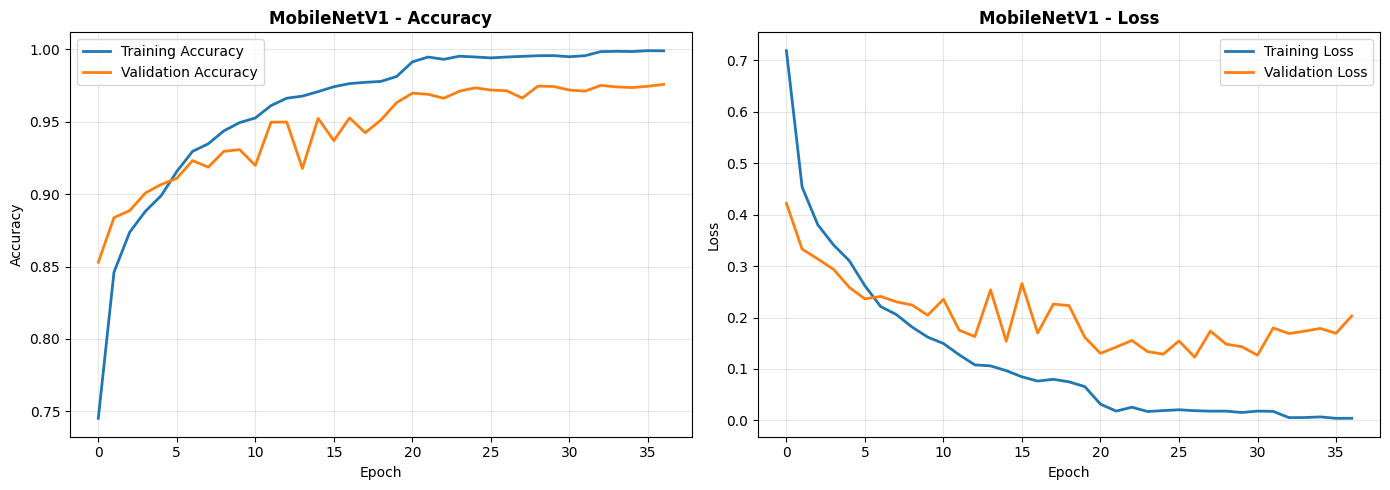

In [35]:
# Plot training history
plot_training_history(history_mobilenet, 'MobileNetV1')


Evaluating MobileNetV1 on Test Set
Test Loss: 0.1017
Test Accuracy: 0.9777

Classification Report:

              precision    recall  f1-score   support

           0     0.9867    0.9832    0.9849       832
           1     0.9865    1.0000    0.9932       146
           2     0.9863    0.9877    0.9870      2772
           3     0.9902    0.9849    0.9875      1126
           4     0.9605    0.9853    0.9727      1973
           5     0.9896    1.0000    0.9948        95
           6     0.9655    0.9805    0.9730       257
           7     0.9625    0.8889    0.9242       693

    accuracy                         0.9777      7894
   macro avg     0.9785    0.9763    0.9772      7894
weighted avg     0.9777    0.9777    0.9775      7894



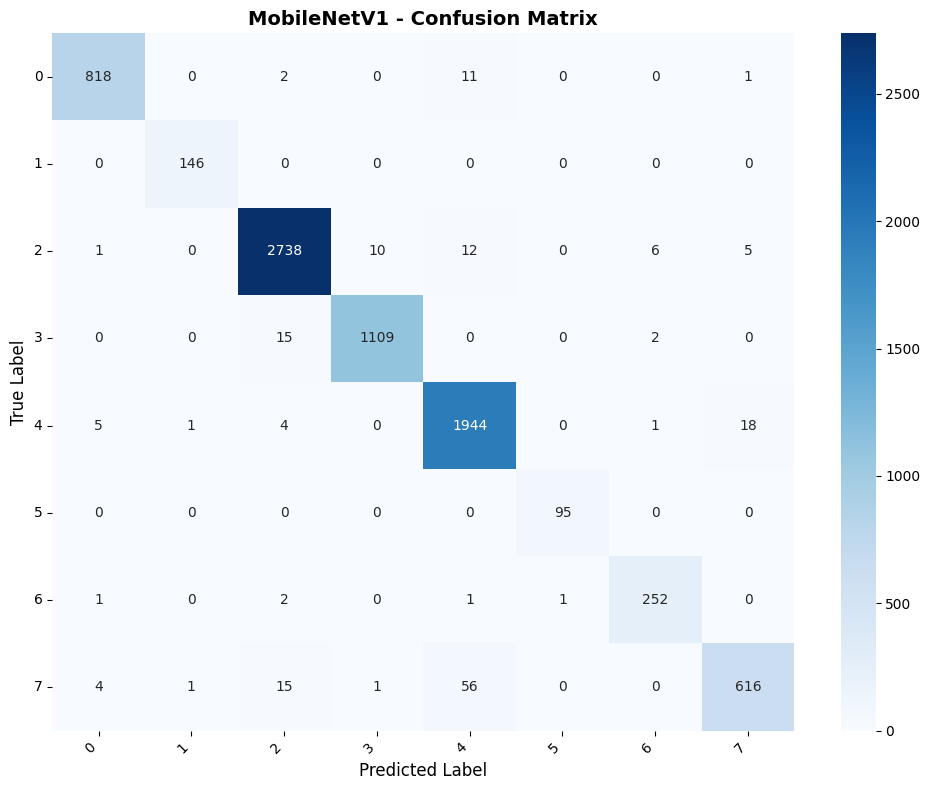

In [36]:
# Evaluate MobileNet-V1 on test set
mobilenet_test_loss, mobilenet_test_acc = evaluate_model(model_mobilenet, 'MobileNetV1', X_test, y_test)

## 9. Model 5: MobileNetV3-Small
### Build, Train, and Test MobileNetV3-Small

In [37]:
# Build MobileNetV3-Small
print("Building MobileNetV3-Small model...")
base_mobilenetv3 = MobileNetV3Small(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
model_mobilenetv3 = add_custom_classification_head(base_mobilenetv3, NUM_CLASSES)

# Model summary
print(f"\nTotal Parameters: {model_mobilenetv3.count_params():,}")
model_mobilenetv3.summary()

Building MobileNetV3-Small model...
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Total Parameters: 957,848


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 32, 32, 3) │          0 │ input_layer_3[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 16, 16,    │        432 │ rescaling_2[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 16, 16,    │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 16, 16,    │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 17, 17,    │          0 │ activation[0][0]  │
│ (ZeroPadding2D)     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 8, 8, 16)  │        144 │ expanded_conv_de… │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 8, 8, 16)  │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 8, 8, 16)  │          0 │ expanded_conv_de… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │          0 │ re_lu[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │        136 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │          0 │ expanded_conv_sq… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │        144 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1, 1, 16)  │          0 │ expanded_conv_sq… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 1, 1, 16)  │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 1, 1, 16)  │          0 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 8, 8, 16)  │          0 │ re_lu[0][0],      │
│ (Multiply)          │                   │            │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 8, 8, 16)  │        256 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                 

 Total params: 957,848 (3.65 MB)

 Trainable params: 945,736 (3.61 MB)

 Non-trainable params: 12,112 (47.31 KB)

In [38]:
# Compile MobileNetV3-Small
model_mobilenetv3.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train MobileNetV3-Small
print("\n" + "="*70)
print("Training MobileNetV3-Small")
print("="*70)

history_mobilenetv3 = model_mobilenetv3.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=get_callbacks('MobileNetV3-Small', OUTPUT_DIR),
    verbose=1
)

print("\nMobileNetV3-Small training completed!")


Training MobileNetV3-Small
Epoch 1/50
1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5486 - loss: 1.4203
Epoch 1: val_accuracy improved from -inf to 0.38151, saving model to outputs/comparison_models/MobileNetV3-Small_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 74s 19ms/step - accuracy: 0.5488 - loss: 1.4196 - val_accuracy: 0.3815 - val_loss: 2.6103 - learning_rate: 0.0010
Epoch 2/50
1323/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8016 - loss: 0.5722
Epoch 2: val_accuracy did not improve from 0.38151
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.8016 - loss: 0.5722 - val_accuracy: 0.0426 - val_loss: 3.3961 - learning_rate: 0.0010
Epoch 3/50
1322/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8425 - loss: 0.4493
Epoch 3: val_accuracy did not improve from 0.38151
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.8425 - loss: 0.4493 - val_accuracy: 0.0425 - val_loss: 12.2066 - learning_rate: 0.0010
Epoch 4/50
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 0

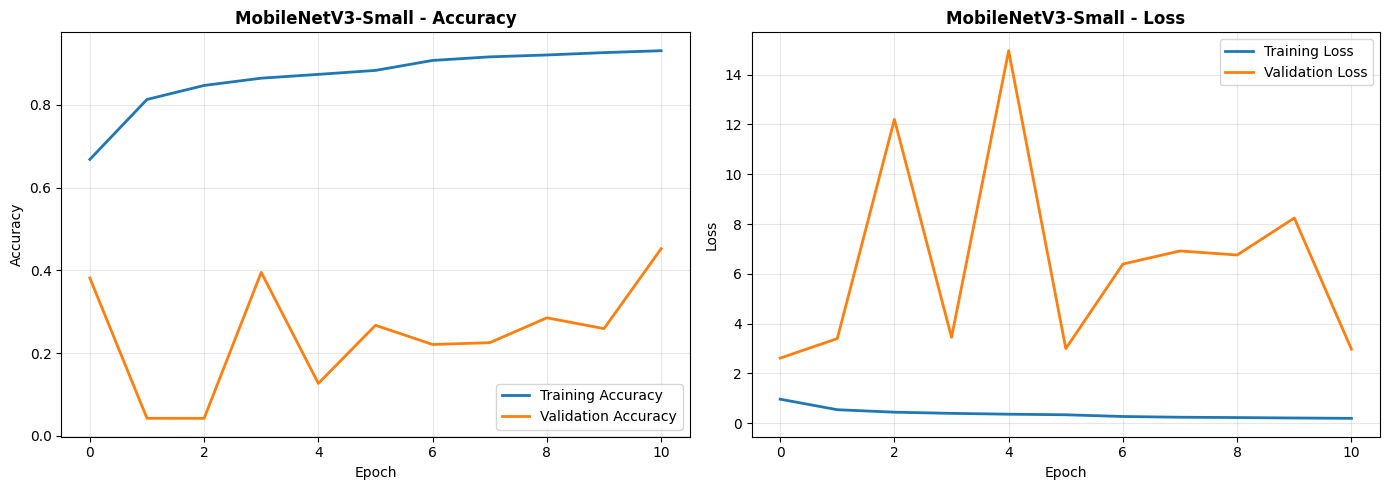

In [39]:
# Plot training history
plot_training_history(history_mobilenetv3, 'MobileNetV3-Small')


Evaluating MobileNetV3-Small on Test Set
Test Loss: 3.1807
Test Accuracy: 0.1472

Classification Report:

              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000       832
           1     0.0000    0.0000    0.0000       146
           2     0.0000    0.0000    0.0000      2772
           3     0.1458    1.0000    0.2544      1126
           4     0.0000    0.0000    0.0000      1973
           5     0.2130    0.3789    0.2727        95
           6     0.0000    0.0000    0.0000       257
           7     0.0000    0.0000    0.0000       693

    accuracy                         0.1472      7894
   macro avg     0.0448    0.1724    0.0659      7894
weighted avg     0.0234    0.1472    0.0396      7894



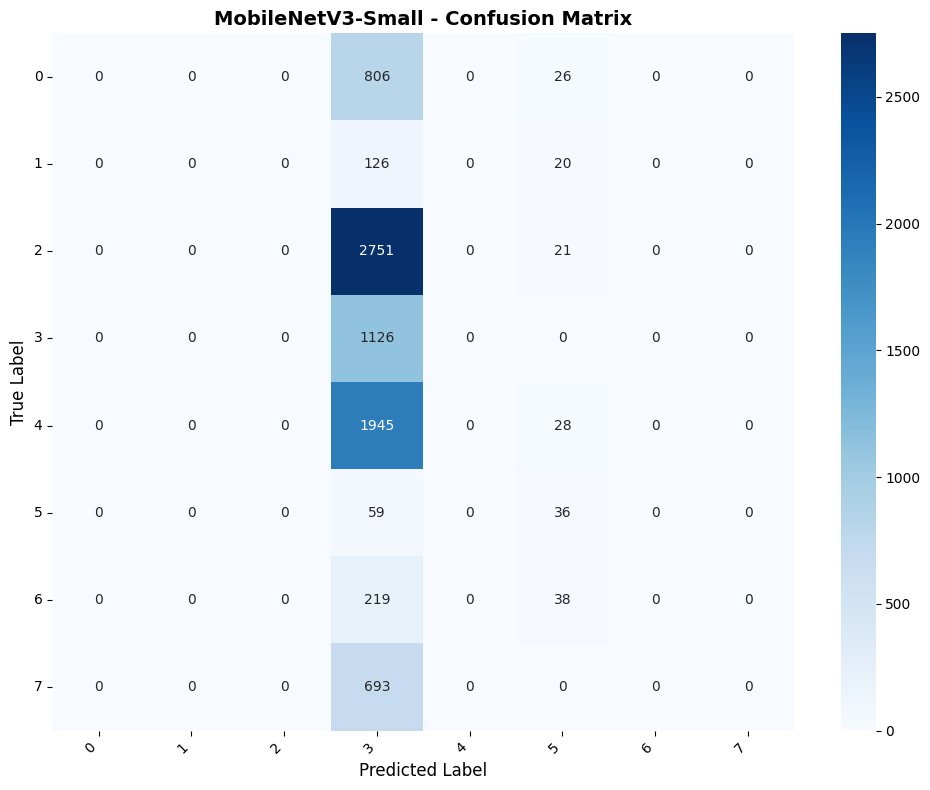

In [40]:
# Evaluate MobileNetV3-Small on test set
mobilenetv3_test_loss, mobilenetv3_test_acc = evaluate_model(model_mobilenetv3, 'MobileNetV3-Small', X_test, y_test)

## 10. Model 6: MobileNetV2-0.5×
### Build, Train, and Test MobileNetV2-0.5×

In [41]:
# Build MobileNetV2-0.5×
print("Building MobileNetV2-0.5× model...")
base_mobilenetv2 = MobileNetV2(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE, alpha=0.5)
model_mobilenetv2 = add_custom_classification_head(base_mobilenetv2, NUM_CLASSES)

# Model summary
print(f"\nTotal Parameters: {model_mobilenetv2.count_params():,}")
model_mobilenetv2.summary()

Building MobileNetV2-0.5× model...
3201480/3201480 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Total Parameters: 747,480


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 16, 16,    │        432 │ input_layer_4[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 16, 16,    │         64 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 16, 16,    │          0 │ bn_Conv1[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 16, 16,    │        144 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 16, 16,    │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 16, 16,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 16, 16, 8) │        128 │ expanded_conv_de… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 16, 16, 8) │         32 │ expanded_conv_pr… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 16, 16,    │        384 │ expanded_conv_pr… │
│ (Conv2D)            │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 16, 16,    │        192 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 16, 16,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 17, 17,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 8, 8, 48)  │        432 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 8, 8, 48)  │        192 │ block_1_depthwis… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 8, 8, 48)  │          0 │ block_1_depthwis… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 8, 8, 16)  │        768 │ block_1_depthwis

 Total params: 747,480 (2.85 MB)

 Trainable params: 728,936 (2.78 MB)

 Non-trainable params: 18,544 (72.44 KB)

In [42]:
# Compile MobileNetV2-0.5×
model_mobilenetv2.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train MobileNetV2-0.5×
print("\n" + "="*70)
print("Training MobileNetV2-0.5×")
print("="*70)

history_mobilenetv2 = model_mobilenetv2.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=get_callbacks('MobileNetV2-0.5x', OUTPUT_DIR),
    verbose=1
)

print("\nMobileNetV2-0.5× training completed!")


Training MobileNetV2-0.5×
Epoch 1/50
1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6523 - loss: 1.0027
Epoch 1: val_accuracy improved from -inf to 0.14925, saving model to outputs/comparison_models/MobileNetV2-0.5x_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 75s 18ms/step - accuracy: 0.6525 - loss: 1.0023 - val_accuracy: 0.1492 - val_loss: 2.7152 - learning_rate: 0.0010
Epoch 2/50
1324/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8248 - loss: 0.5251
Epoch 2: val_accuracy improved from 0.14925 to 0.76925, saving model to outputs/comparison_models/MobileNetV2-0.5x_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.8248 - loss: 0.5250 - val_accuracy: 0.7692 - val_loss: 0.6584 - learning_rate: 0.0010
Epoch 3/50
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8619 - loss: 0.4207
Epoch 3: val_accuracy improved from 0.76925 to 0.79311, saving model to outputs/comparison_models/MobileNetV2-0.5x_best.keras
1325/1325 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/s

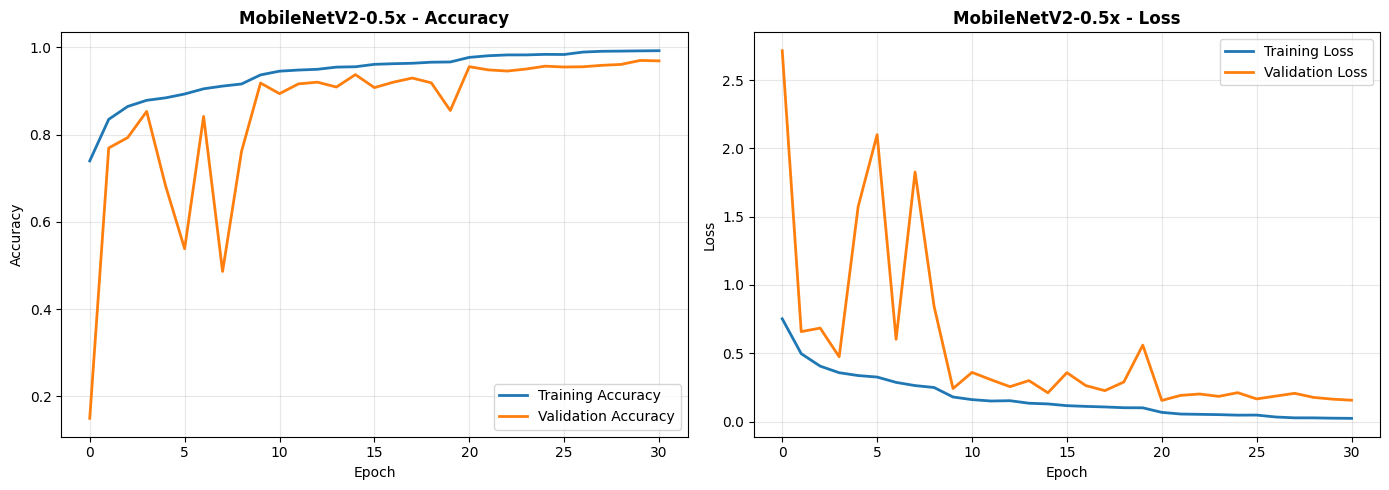

In [43]:
# Plot training history
plot_training_history(history_mobilenetv2, 'MobileNetV2-0.5x')


Evaluating MobileNetV2-0.5x on Test Set
Test Loss: 0.1979
Test Accuracy: 0.9359

Classification Report:

              precision    recall  f1-score   support

           0     0.9627    0.9627    0.9627       832
           1     0.9182    1.0000    0.9574       146
           2     0.9777    0.9336    0.9552      2772
           3     0.9601    0.9822    0.9710      1126
           4     0.8789    0.9524    0.9141      1973
           5     0.9694    1.0000    0.9845        95
           6     0.9259    0.9728    0.9488       257
           7     0.8746    0.7547    0.8102       693

    accuracy                         0.9359      7894
   macro avg     0.9334    0.9448    0.9380      7894
weighted avg     0.9370    0.9359    0.9354      7894



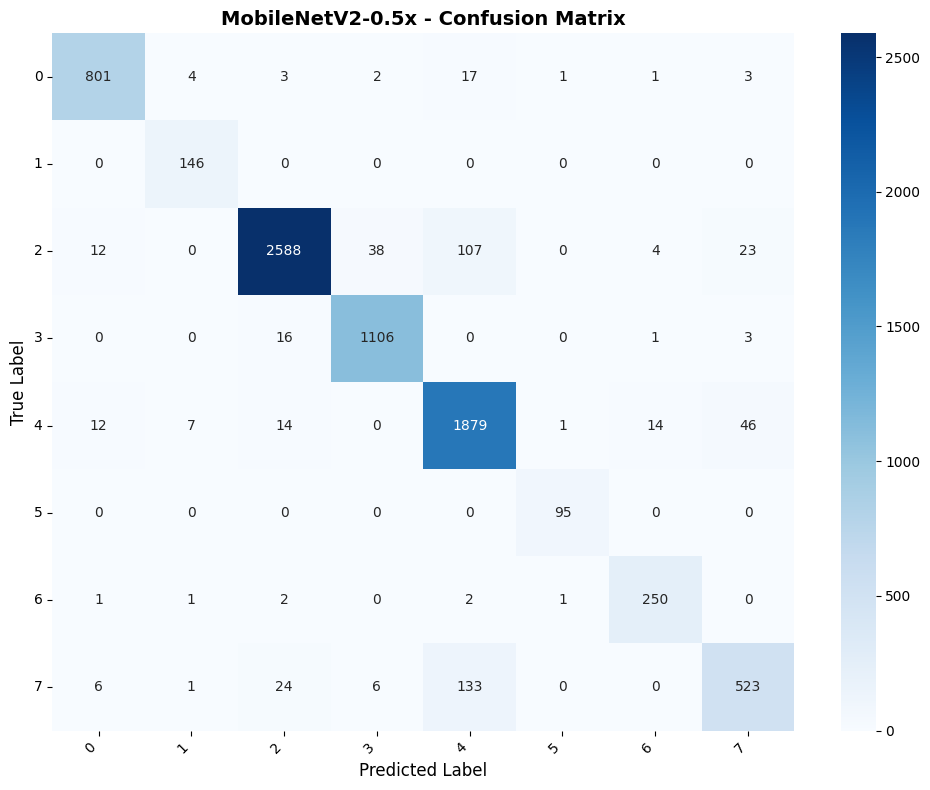

In [44]:
# Evaluate MobileNetV2-0.5× on test set
mobilenetv2_test_loss, mobilenetv2_test_acc = evaluate_model(model_mobilenetv2, 'MobileNetV2-0.5x', X_test, y_test)

## 11. Final Comparison of All Models

In [45]:
# Compile all results
comparison_data = [
    {
        'Model': 'VGG16',
        'Parameters': model_vgg16.count_params(),
        'Test Accuracy': vgg16_test_acc,
        'Test Loss': vgg16_test_loss
    },
    {
        'Model': 'ResNet18',
        'Parameters': sum(p.numel() for p in model_resnet18_pytorch.parameters()),
        'Test Accuracy': resnet18_test_acc,
        'Test Loss': resnet18_test_loss
    },
    {
        'Model': 'EfficientNetB0',
        'Parameters': model_effnet.count_params(),
        'Test Accuracy': effnet_test_acc,
        'Test Loss': effnet_test_loss
    },
    {
        'Model': 'MobileNetV1',
        'Parameters': model_mobilenet.count_params(),
        'Test Accuracy': mobilenet_test_acc,
        'Test Loss': mobilenet_test_loss
    },
    {
        'Model': 'MobileNetV3-Small',
        'Parameters': model_mobilenetv3.count_params(),
        'Test Accuracy': mobilenetv3_test_acc,
        'Test Loss': mobilenetv3_test_loss
    },
    {
        'Model': 'MobileNetV2-0.5x',
        'Parameters': model_mobilenetv2.count_params(),
        'Test Accuracy': mobilenetv2_test_acc,
        'Test Loss': mobilenetv2_test_loss
    }
]

# Create DataFrame
comparison_df = pd.DataFrame(comparison_data)
comparison_df['Size (MB)'] = (comparison_df['Parameters'] * 4) / (1024 * 1024)
comparison_df = comparison_df.sort_values('Test Accuracy', ascending=False)

print("\n" + "="*80)
print("FINAL MODEL COMPARISON TABLE")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Save to CSV
comparison_path = os.path.join(OUTPUT_DIR, 'final_model_comparison.csv')
comparison_df.to_csv(comparison_path, index=False)
print(f"\nComparison table saved to: {comparison_path}")


FINAL MODEL COMPARISON TABLE
            Model  Parameters  Test Accuracy  Test Loss  Size (MB)
         ResNet18    11193192       0.986065   0.157331  42.698639
      MobileNetV1     3261928       0.977705   0.101707  12.443268
            VGG16    14718792       0.955409   0.172061  56.147736
 MobileNetV2-0.5x      747480       0.935901   0.197891   2.851410
   EfficientNetB0     4059819       0.469344   1.455053  15.486980
MobileNetV3-Small      957848       0.147200   3.180722   3.653900

Comparison table saved to: outputs/comparison_models/final_model_comparison.csv


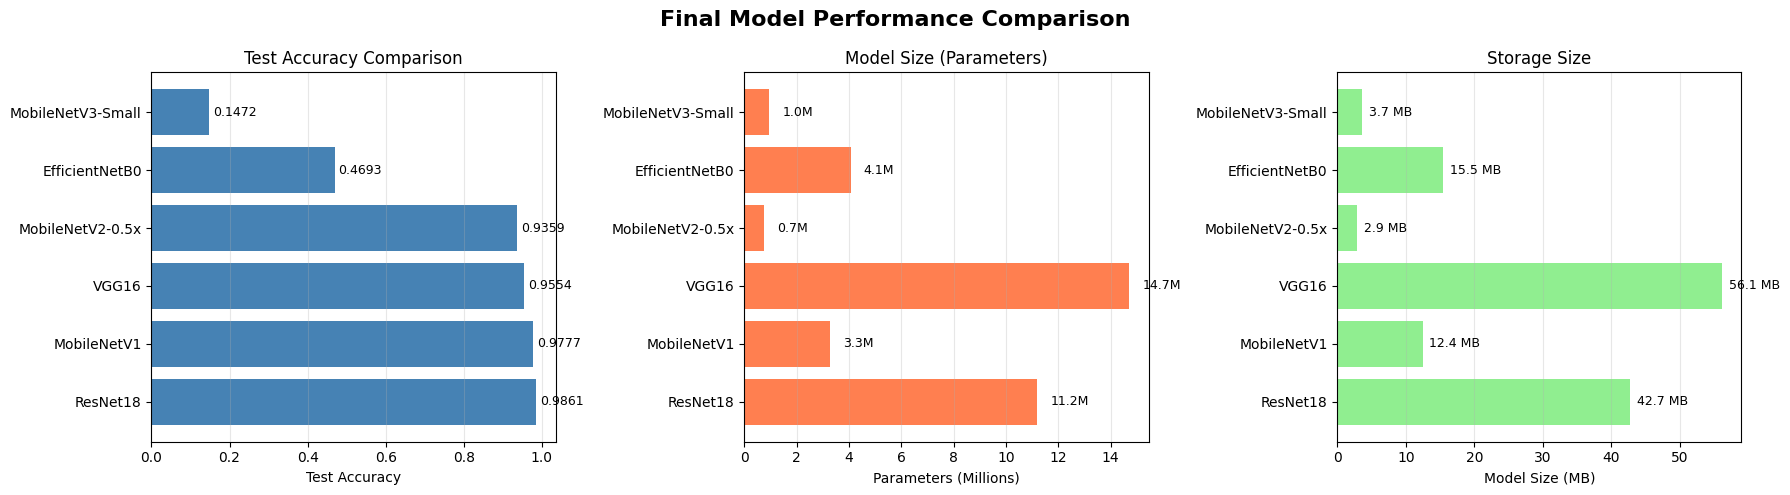

Final comparison plot saved to: outputs/comparison_models/final_comparison.png


In [46]:
# Create comparison visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Final Model Performance Comparison', fontsize=16, fontweight='bold')

models = comparison_df['Model'].tolist()
params = comparison_df['Parameters'].tolist()
test_accs = comparison_df['Test Accuracy'].tolist()
sizes = comparison_df['Size (MB)'].tolist()

# Plot 1: Test Accuracy
axes[0].barh(models, test_accs, color='steelblue')
axes[0].set_xlabel('Test Accuracy')
axes[0].set_title('Test Accuracy Comparison')
axes[0].grid(axis='x', alpha=0.3)
for i, v in enumerate(test_accs):
    axes[0].text(v + 0.01, i, f'{v:.4f}', va='center', fontsize=9)

# Plot 2: Parameters
axes[1].barh(models, [p/1e6 for p in params], color='coral')
axes[1].set_xlabel('Parameters (Millions)')
axes[1].set_title('Model Size (Parameters)')
axes[1].grid(axis='x', alpha=0.3)
for i, v in enumerate(params):
    axes[1].text(v/1e6 + 0.5, i, f'{v/1e6:.1f}M', va='center', fontsize=9)

# Plot 3: Model Size (MB)
axes[2].barh(models, sizes, color='lightgreen')
axes[2].set_xlabel('Model Size (MB)')
axes[2].set_title('Storage Size')
axes[2].grid(axis='x', alpha=0.3)
for i, v in enumerate(sizes):
    axes[2].text(v + 1, i, f'{v:.1f} MB', va='center', fontsize=9)

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, 'final_comparison.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Final comparison plot saved to: {plot_path}")